In [1]:
from hamilton import driver
from hamilton.execution import executors

import rayfish
import rayfish.quantum_fisher_information as qfi
from rayfish.classical_fisher_information import (
    incoherent as classical_incoherent_sources,
)
from rayfish.classical_fisher_information.measurement_basis import (
    hermite_gaussian_basis,
)
from rayfish.parameter_catalogue import distance_3_sources_xz
from rayfish.quantum_fisher_information import (
    incoherent_sources as qfi_incoherent_sources,
)

In [2]:
conf = {
    "simulation_dimension": 1,
}

input_ = {
    "wave_vector": 2.0,
    "rayleigh_length": 1.0,
    "number_of_grids": 50,
    "maximal_length": 14.0,
    "minimal_spacing": 0.1,
    "min_z_displacement": 0.1,
    "max_z_displacement": 2.0,
    "number_of_modes": 10,
}

In [3]:
quantum_dr = (
    driver.Builder()
    .with_modules(rayfish, qfi, qfi_incoherent_sources, distance_3_sources_xz)
    .with_config(config=conf)
    .enable_dynamic_execution(allow_experimental_mode=True)
    .with_local_executor(executors.SynchronousLocalTaskExecutor())
).build()

classical_dr = (
    driver.Builder()
    .with_modules(
        rayfish,
        classical_incoherent_sources,
        distance_3_sources_xz,
        hermite_gaussian_basis,
    )
    .with_config(config=conf)
).build()

In [4]:
quantum_result = quantum_dr.execute(
    inputs=input_,
    final_vars=[
        "fisher_information_matrix_for_entire_distribution",
        "covariance_matrix_for_entire_distribution",
        "number_of_point_sources",
        "spacing",
        "coordinates",
    ],
)

classical_result = classical_dr.execute(
    inputs=input_,
    final_vars=[
        "fisher_information_matrix_for_entire_distribution",
        "covariance_matrix_for_entire_distribution",
        "number_of_point_sources",
        "spacing",
        "coordinates",
    ],
)

In [5]:
import numpy as np

In [45]:
qfi_ = np.real(
    quantum_result["fisher_information_matrix_for_entire_distribution"].reshape(
        50, 50, 2, 2
    )
)
np.save(
    "qfi.npy",
    qfi_,
)

qfi_inv_ = np.real(
    quantum_result["covariance_matrix_for_entire_distribution"].reshape(50, 50, 2, 2)
)
np.save(
    "qfi_inv.npy",
    qfi_inv_,
)
# qfi_ = np.load("qfi.npy")

In [46]:
fi_ms_ = classical_result["fisher_information_matrix_for_entire_distribution"].reshape(
    50, 50, 10, 2, 2
)
np.save(
    "fi_ms.npy",
    fi_ms_,
)

fi_ms_inv_ = classical_result["covariance_matrix_for_entire_distribution"].reshape(
    50, 50, 2, 2
)
np.save(
    "fi_ms_inv.npy",
    fi_ms_inv_,
)
# fi_ms_ = np.load("fi_ms.npy")

In [8]:
coords = quantum_result["coordinates"].reshape(50, 50, 9)
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

In [9]:
%matplotlib inline

In [ ]:
import matplotlib.pyplot as plt

from visualize_helpers import create_fig_and_ax, latexify, plot_individual_fi

In [11]:
latexify()

In [63]:
FORMAT = "pdf"

# s param

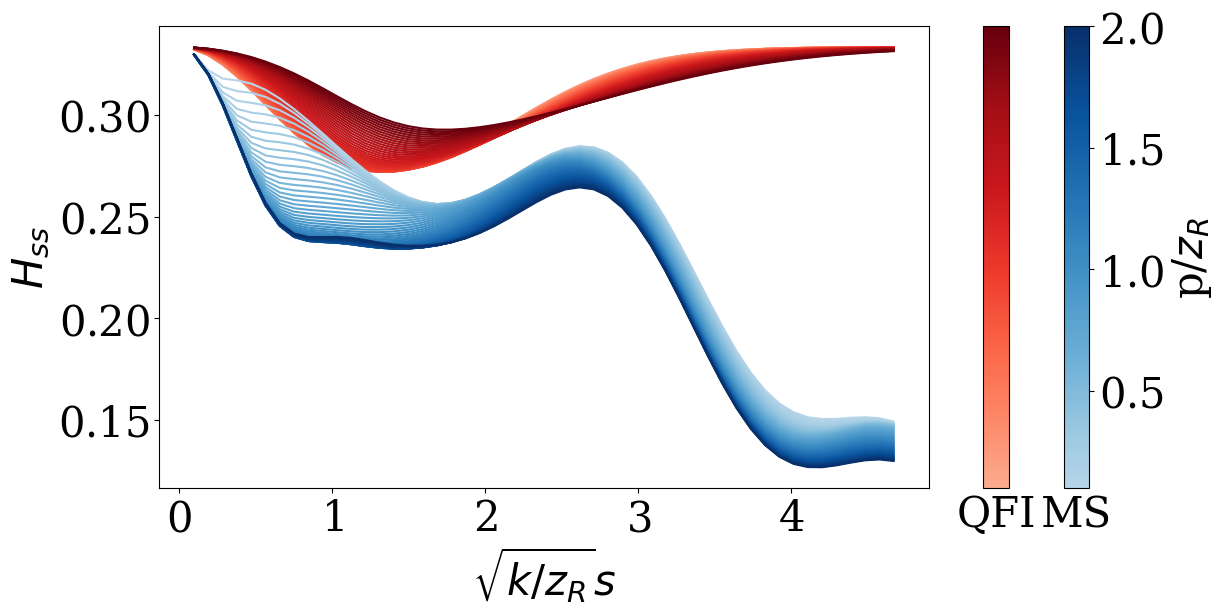

In [64]:
fig, axs = create_fig_and_ax(2)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
ms_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    "Blues",
    2,
    "MS",
    False,
)

axs[2].set_ylabel("p/$z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} s$")
axs[0].set_ylabel(r"$H_{ss}$")

fig.savefig(f"s_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

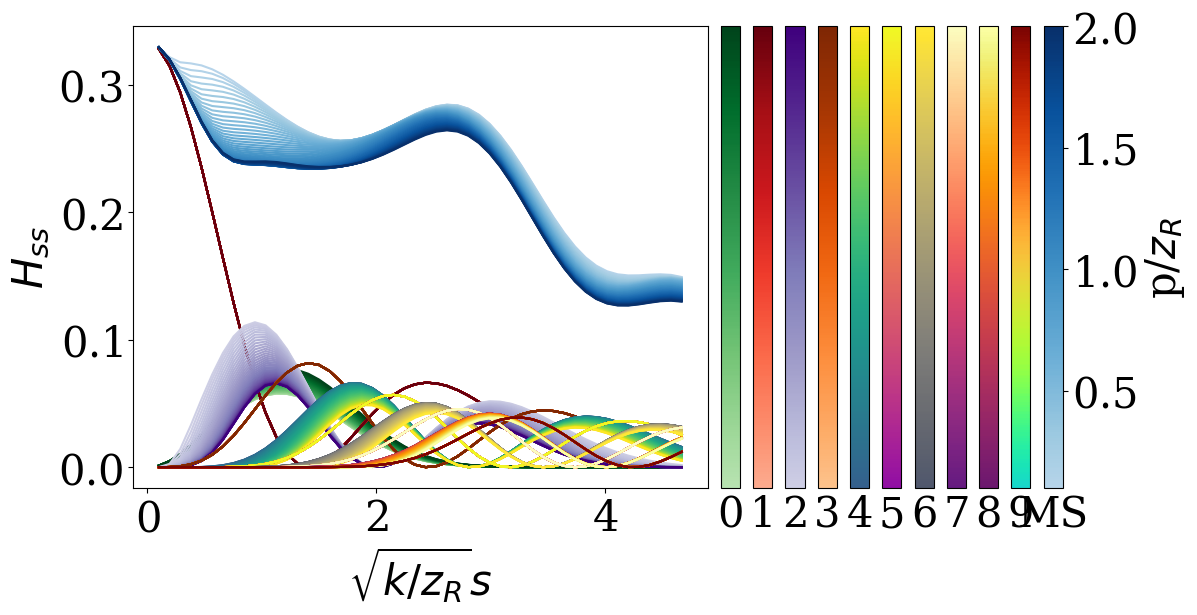

In [ ]:
n_modes = fi_ms_.shape[2]


# Whitelist of continuous colormaps suitable for publication
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]


def filter_pub_friendly_continuous(
    max_rgb: float = 1, sample_points: int = 256
) -> list:
    """Good colors for plots."""
    good_cmaps = []
    for name in continuous_cmaps:
        cmap = plt.get_cmap(name)
        colors = cmap(np.linspace(0, 1, sample_points))[:, :3]  # RGB only
        if np.any(colors > max_rgb):
            continue  # skip overly bright colors
        good_cmaps.append(name)
    return good_cmaps


good_cmaps = filter_pub_friendly_continuous()

fig, axs = create_fig_and_ax(n_modes + 1)
for i in range(n_modes):
    plot_individual_fi(
        fig, axs, fi_ms_[:, :, i, 0, 0], x_range, p_range, good_cmaps[i], i + 1, f"{i}"
    )

sum_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    "Blues",
    n_modes + 1,
    "MS",
    False,
)


axs[n_modes + 1].set_ylabel("p/$z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} s$")
axs[0].set_ylabel(r"$H_{ss}$")

fig.savefig(
    f"s_param_individual_mode_contributions.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

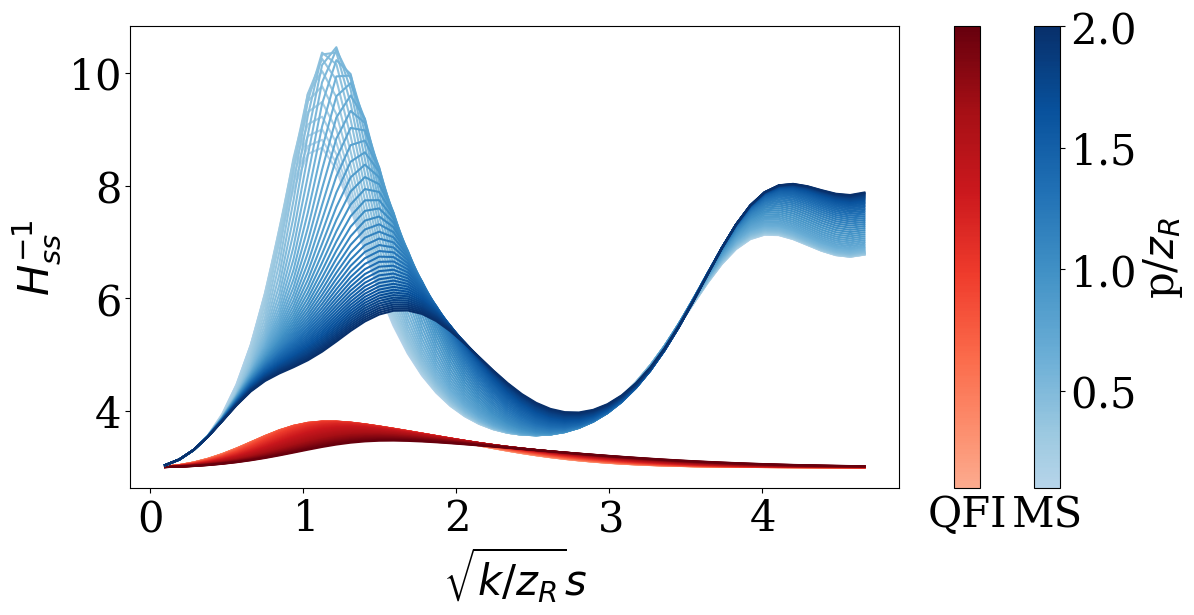

In [66]:
fig, axs = create_fig_and_ax(2)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_inv_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
ms_cm = plot_individual_fi(
    fig, axs, fi_ms_inv_[:, :, 0, 0], x_range, p_range, "Blues", 2, "MS", False
)

axs[2].set_ylabel("p/$z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} s$")
axs[0].set_ylabel(r"$H^{-1}_{ss}$")

fig.savefig(f"s_param_covariance.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

# p param

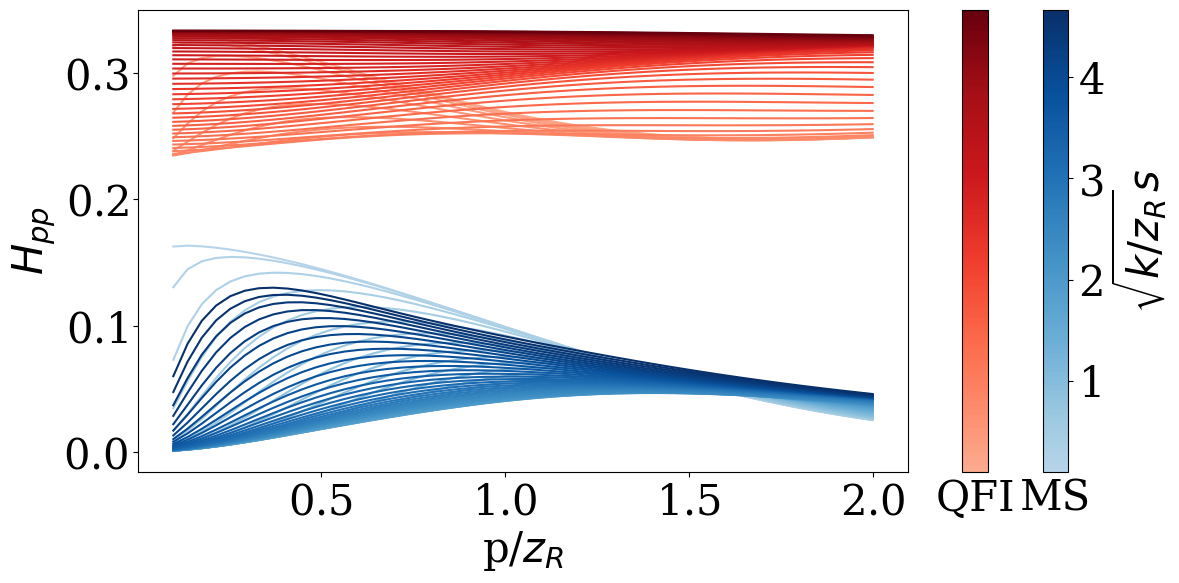

In [67]:
fig, axs = create_fig_and_ax(2)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    2,
    "MS",
    False,
)

axs[2].set_ylabel(r"$\sqrt{k/z_R} s$")
axs[0].set_xlabel(r"p/$z_R$")
axs[0].set_ylabel(r"$H_{pp}$")

fig.savefig(f"p_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")

plt.show()

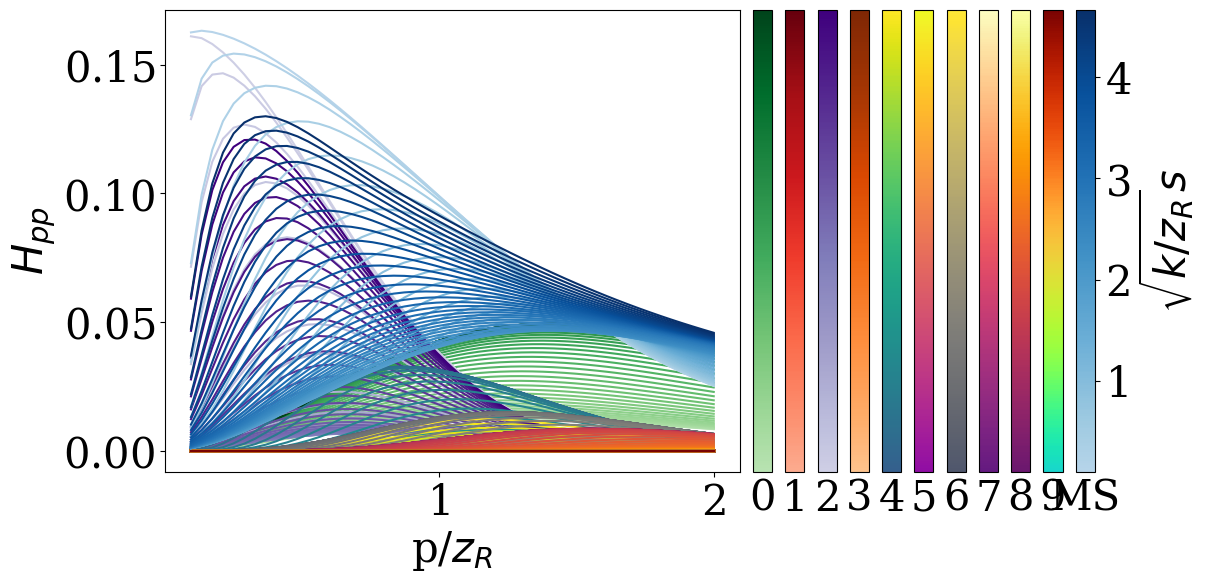

In [68]:
good_cmaps = filter_pub_friendly_continuous()

fig, axs = create_fig_and_ax(n_modes + 1)
for i in range(n_modes):
    plot_individual_fi(
        fig,
        axs,
        np.transpose(fi_ms_[:, :, i, 1, 1]),
        p_range,
        x_range,
        good_cmaps[i],
        i + 1,
        f"{i}",
    )

qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    n_modes + 1,
    "MS",
    False,
)


axs[n_modes + 1].set_ylabel(r"$\sqrt{k/z_R} s$")
axs[0].set_xlabel(r"p/$z_R$")
axs[0].set_ylabel(r"$H_{pp}$")
fig.savefig(
    f"p_param_individual_mode_contributions.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

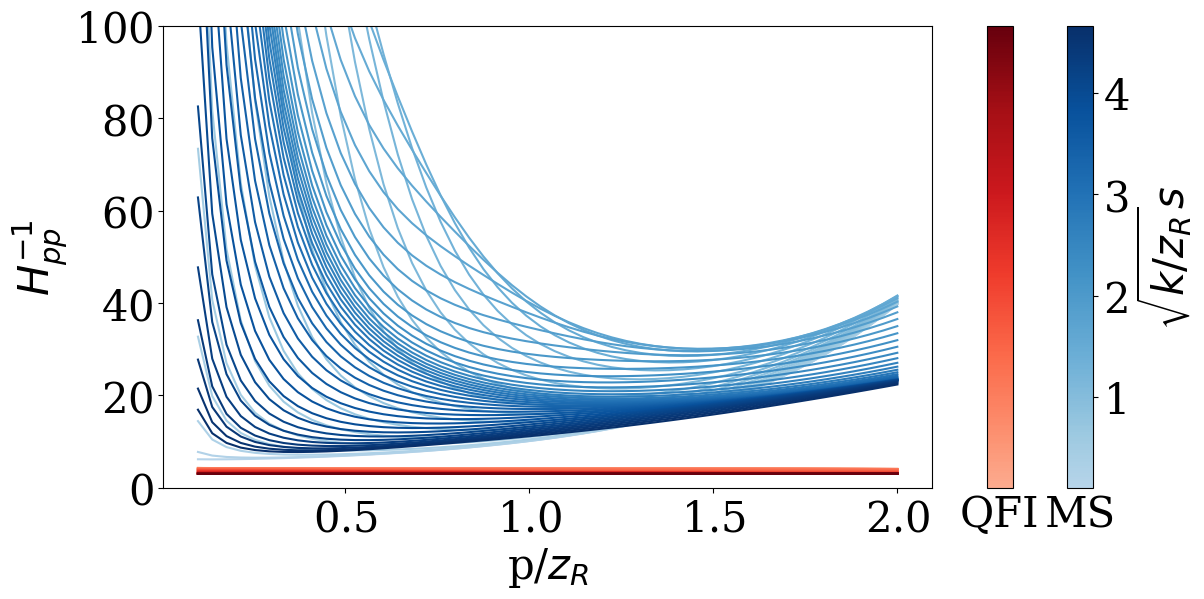

In [69]:
fig, axs = create_fig_and_ax(2)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_inv_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_inv_[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    2,
    "MS",
    False,
)

axs[0].set_ylim(0, 100)
axs[2].set_ylabel(r"$\sqrt{k/z_R} s$")
axs[0].set_xlabel(r"p/$z_R$")
axs[0].set_ylabel(r"$H^{-1}_{pp}$")

fig.savefig(f"p_param_covariance.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()